In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from functools import partial
from importlib import reload

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr

from dask.distributed import wait
# from plotting_modules import formatting
# from plotting_modules.constants import FORCING_COLORS
from extant import config, datatree, loading, paths, preprocessing as pp, storage, zonal
# from extant import quantiles as qc, response_change as rc, significance as sig
# from extant import observed_change as oc, probability_ratio as pr, sam
from extant.logger import setup_logging
# from extant.plots import methods
# from extant.plots import zonal as zp
# from extant.stats import nan_quantile

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Dask warns about every large task graph; the graphs here are large on purpose
warnings.filterwarnings('ignore', message='.*Sending large graph of size.*', category=UserWarning)

In [2]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/fe1fddf0ef964b9eb92dc087a2ce9475/status,


In [3]:
VARIABLE = 'tas'

In [4]:
#(t): The two places the seasonal store can be: DATA_DIR is read first, then SCRATCH
seasonal_store = paths.seasonal('lesfmip', VARIABLE)
pd.Series({str(root / seasonal_store): (root / seasonal_store).exists() for root in (paths.DATA_DIR, paths.SCRATCH)},
          name='exists')

/gws/ssde/j25b/leader_epesc/aborow/ExtAnt/seasonal/lesfmip_tas.zarr    False
/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr               True
Name: exists, dtype: bool

In [5]:
seasonal_path = paths.find(seasonal_store)
seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [6]:
lesfmip_season_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)
/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be suppor

In [8]:
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 227MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * season   (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0

# draft 01

In [32]:
sample_da = lesfmip_season_tree['CanESM5']['hist-nat'].isel(season=2).tas

In [33]:
sample_da

<xarray.DataArray 'tas' (member: 50, lat: 20, lon: 144, year: 164)> Size: 94MB
dask.array<chunksize=(50, 4, 144, 164), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    season   <U3 12B 'MAM'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'

In [34]:
base_climatology = sample_da.mean(dim=['year', 'member']).compute()

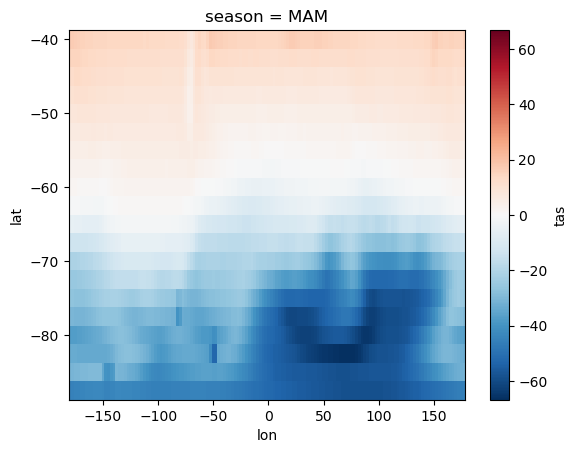

In [35]:
base_climatology.plot()

In [36]:
rolling_da = sample_da.rolling(year=21, center=True, min_periods=21).construct('window')

In [37]:
rolling_da

<xarray.DataArray 'tas' (member: 50, lat: 20, lon: 144, year: 164, window: 21)> Size: 2GB
dask.array<chunksize=(13, 2, 36, 163, 21), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    season   <U3 12B 'MAM'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
Dimensions without coordinates: window

In [38]:
rolling_da_base = rolling_da.mean(dim=['member', 'window']).compute()

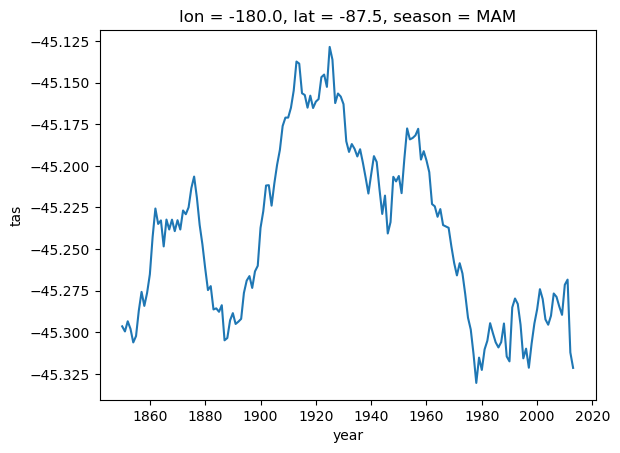

In [39]:
rolling_da_base.isel(lat=0, lon=0).plot()

In [40]:
from itertools import combinations

In [84]:
N_TRIALS = 500

In [85]:
n_members = 10

In [86]:
ensemble_combinations = np.random.choice(sample_da.sizes['member'], size=(N_TRIALS, n_members), replace=True)

In [87]:
ensemble_combinations.shape

(500, 10)

In [88]:
idx_da = xr.DataArray(ensemble_combinations, dims=('trial', 'member'))

In [89]:
idx_da

<xarray.DataArray (trial: 500, member: 10)> Size: 40kB
38 15 5 26 27 28 47 6 33 8 14 47 47 29 ... 5 31 27 28 30 46 30 25 3 36 30 27 16
Dimensions without coordinates: trial, member

In [90]:
from numba import njit, prange

In [91]:
@njit
def _trial_year_member_mean(arr, window=21):
    n_members, n_years = arr.shape
    n_repeats = n_years-21
    n_points = n_years * n_members
    values = np.empty(n_repeats)
    
    for i in prange(n_repeats):
        end = i + window
        values[i] = np.sum(arr[:][i:i+window])

    values = values/n_points

    return values
        

In [117]:
def member_mapblocks(ds):
    njit_member_mean = xr.apply_ufunc(
        _trial_year_member_mean,
        ds,
        input_core_dims=[['member', 'year']],
        output_core_dims = [['year2']],
        vectorize=True,
        dask='parallelized',
        output_dtypes=[float],
        dask_gufunc_kwargs={"output_sizes": {"year2": ds.sizes['year']-21}},

        )

    return njit_member_mean
    

In [118]:
sample_da

<xarray.DataArray 'tas' (member: 50, lat: 20, lon: 144, year: 164)> Size: 94MB
dask.array<chunksize=(50, 4, 144, 164), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    season   <U3 12B 'MAM'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'

In [112]:
sample_da_idx = sample_da.isel(member=idx_da)

In [119]:
# sample_da_idx = sample_da_idx.chunk({'member':-1, 'window':-1, 'lat':-1, 'lon': -1, 'trial':})

In [120]:
sample_da_idx

<xarray.DataArray 'tas' (trial: 500, member: 10, lat: 20, lon: 144, year: 164)> Size: 9GB
dask.array<chunksize=(5, 10, 4, 144, 164), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    season   <U3 12B 'MAM'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    member   (trial, member) object 40kB 'r4i1p1f1' 'r17i1p2f1' ... 'r18i1p1f1'
Dimensions without coordinates: trial

In [121]:
rolling_da_bootstrap_anom = member_mapblocks(sample_da_idx)

In [122]:
rolling_da_bootstrap_anom = rolling_da_bootstrap_anom.compute()

In [123]:
rolling_da_bootstrap_anom = rolling_da_bootstrap_anom.rename({'year2':'year'})

In [124]:
rolling_da_bootstrap_anom['year'] = sample_da_idx.year.values[11:-10]

In [125]:
rolling_da_bootstrap_anom = rolling_da_bootstrap_anom - rolling_da_base

In [126]:
uncertainty_da = rolling_da_bootstrap_anom.std(dim=['trial', 'year'])

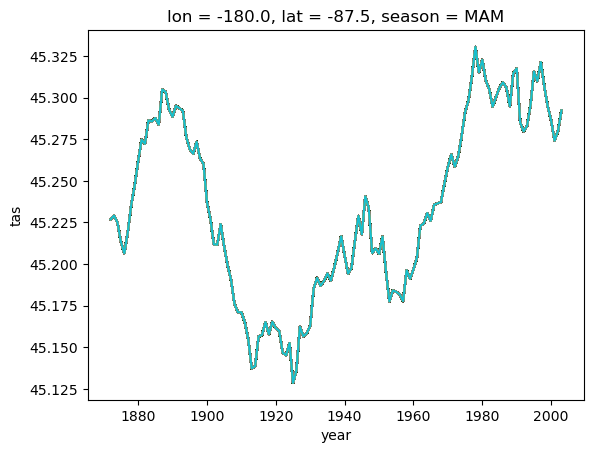

In [127]:
rolling_da_bootstrap_anom.isel(lat=0, lon=0).isel(year=slice(11, None)).plot(hue='trial', add_legend=False);

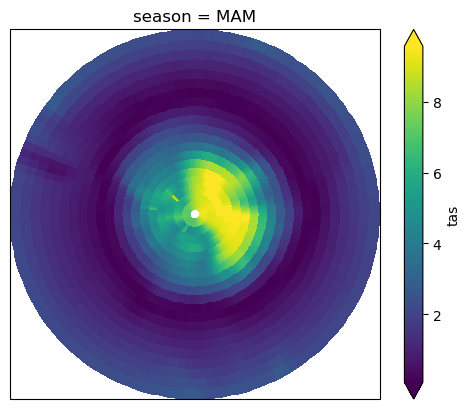

In [128]:
uncertainty_da.plot(robust=True, subplot_kws=dict(projection=ccrs.SouthPolarStereo()), transform=ccrs.PlateCarree())

In [75]:
njit_member_mean = xr.apply_ufunc(
    _trial_year_member_mean,
    sample_da_idx,
    input_core_dims=[['member', 'year']],
    output_core_dims = [['year']],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[float]
    
).compute()

2026-10-15 16:29:51,607 - distributed.client - WARNING - Couldn't gather 1 keys, rescheduling ('finalize-hlgfinalizecompute-c4dccdbf6b58400d9d830dda623734a9',)


FutureCancelledError: finalize-hlgfinalizecompute-c4dccdbf6b58400d9d830dda623734a9 cancelled for reason: scheduler-connection-lost.
Client lost the connection to the scheduler. Please check your connection and re-run your work.

In [52]:
njit_member_mean

<xarray.DataArray 'tas' (trial: 1000, lat: 20, lon: 144, year: 164)> Size: 945MB
dask.array<chunksize=(10, 4, 144, 164), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    season   <U3 12B 'MAM'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
Dimensions without coordinates: trial

In [22]:
rolling_da_bootstrap = rolling_da.isel(member=idx_da).chunk({'member':-1, 'window':-1, 'lat':-1, 'lon': -1})

In [23]:
rolling_da_bootstrap

<xarray.DataArray 'tas' (trial: 1000, member: 5, lat: 20, lon: 144, year: 164,
                         window: 21)> Size: 198GB
dask.array<chunksize=(2, 5, 20, 144, 163, 21), meta=np.ndarray>
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    season   <U3 12B 'MAM'
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
    member   (trial, member) object 40kB dask.array<chunksize=(1000, 5), meta=np.ndarray>
Dimensions without coordinates: trial, window

In [27]:
rolling_da_bootstrap_mean = rolling_da_bootstrap.mean(dim=['window', 'member']).compute()

In [28]:
rolling_da_bootstrap_anom = rolling_da_bootstrap_mean - base_climatology

boostrap_ensemble_size_uncertainty?

In [ ]:
rolling_da_bootstrap_anom = boostrap_ensemble_size_uncertainty(sample_da, base_climatology, 10, 599)

In [ ]:
rolling_da_bootstrap_anom.isel(lat=0, lon=0).plot(hue='trial', add_legend=False);

In [41]:
combinations?

Init signature: combinations(iterable, r)
Docstring:     
Return successive r-length combinations of elements in the iterable.

combinations(range(4), 3) --> (0,1,2), (0,1,3), (0,2,3), (1,2,3)
Type:           type
Subclasses:     

In [18]:
# ensemble_combinations = np.array(list(combinations(np.arange(0, 50), 5)))
# ensemble_combinations = ensemble_combinations[:200, :]

In [19]:
def boostrap_ensemble_size_uncertainty(da, base_climatology, window_size:int, n_trials:int)-> xr.Dataset:
    ensemble_combinations = np.random.choice(da.sizes['member'], size=(n_trials, n_trials), replace=True)

    idx_da = xr.DataArray(ensemble_combinations, dims=('trial', 'member'))

    rolling_da_bootstrap = rolling_da.isel(member=idx_da).chunk({'member':-1, 'window':-1})

    rolling_da_bootstrap_mean = rolling_da_bootstrap.mean(dim=['window', 'member']).compute()

    rolling_da_bootstrap_anom = rolling_da_bootstrap_mean - base_climatology

    return rolling_da_bootstrap_anom

In [ ]:
idx = np.argsort(rng.random((n_trials, n_members)), axis=1)[:, :n_samples]

In [ ]:
def _trial_qrange(data, selected, q_low, q_high, out):
    """``out[s, t]``: the Q-range of trial t's members, all their years pooled, at point s.

    Each point's values are sorted once, for every trial.

    Args:f

In [ ]:
        data (np.ndarray): (point, member, year).
        selected (np.ndarray): (trial, member) True for the members each trial samples.
    """
    n_points, n_members, n_years = data.shape
    for s in prange(n_points):
        values = np.empty(n_members * n_years)
        members = np.empty(n_members * n_years, dtype=np.int64)
        counts = np.empty(n_members, dtype=np.int64)
        n_valid = _sorted_pool(data[s], values, members, counts)
        for t in range(selected.shape[0]):
            n_group = 0
            for m in range(n_members):
                if selected[t, m]:
                    n_group += counts[m]
            out[s, t] = _group_qrange(values, members, n_valid, selected[t], n_group, q_low, q_high).